# Complexity-04d — Le secrétaire matroïdal : la conjecture mesurée élément par élément

[Source Python](Complexity-04d-Secretaire-Matroidal-Python.ipynb) · [04b — Les deux conjectures online](Complexity-04b-OnlineConjectures-Secretary-KServer-Python.ipynb) · [04c — k-server et work function](Complexity-04c-KServer-WorkFunction-Python.ipynb) · [Index de la série](README.md)

**Positionnement.** Après le secrétaire classique et la synthèse 04b, ce carnet suit le problème où l'on peut accepter plusieurs éléments, mais seulement sous une contrainte d'indépendance. Le notebook Python rapporte la conjecture de Babaioff–Immorlica–Kleinberg (2007) et l'annonce attribuée à Sahil Singla (*The Matroid Secretary Conjecture is True*, prépublication de 2026). Il présente une garantie élément par élément et un algorithme explicite. Les expériences suivantes reconstruisent les objets décrits par ce Python sur de petites instances ; elles ne démontrent pas le théorème général.

Le **Python versionné** est la source consultée pour ce port. Son récit et ses attributions aux publications sont rapportés comme tels : aucune lecture directe de la prépublication ou des autres documents n'est revendiquée ici. Les chiffres C# sont **mesurés** dans les cellules, tandis que la garantie générale est **rapportée**, sans preuve reproduite. La bibliothèque native .NET suffit pour les oracles et l'algorithme ; le graphique utilise les fréquences calculées et un SVG inline.

**Objectifs.** Formuler le secrétaire classique et sa variante matroïdale ; manipuler les oracles uniforme, de partition et graphique ; comprendre l'échantillon binomial, l'ordre virtuel et la comparaison des gloutons ; mesurer les fréquences de chaque élément de l'optimum, le ratio moyen et la différence avec le secrétaire classique ; utiliser une garantie annoncée comme test sans la confondre avec une preuve. **Prérequis** : tri, ensembles, forêt et décision en ligne ; 04b et 04c donnent le contexte. **Durée pédagogique** : 40 minutes.

Les huit poids, classes, quotas et arêtes du source sont conservés. Les graines `System.Random` sont fixes, mais leurs suites ne sont pas celles de `random` Python : les budgets et instances sont comparables, pas chaque tirage ni chaque fréquence chiffrée.

In [1]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Numerics;
using System.Globalization;

// Éviter une virgule décimale dans les attributs numériques du SVG, même après changement de thread.
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;
Console.WriteLine("Structures et générateur .NET prêts");


Structures et générateur .NET prêts


## 1. Du secrétaire classique aux trois matroïdes

Dans le problème classique, les candidats arrivent en ordre aléatoire, un refus ne peut être repris et le but est de recruter le meilleur. La règle de seuil observe environ $n/e$ candidats puis choisit le premier qui bat le maximum observé ; $1/e$ est sa limite asymptotique. Le cas uniforme de rang 1 en est une variante : accepter deux éléments est interdit.

La variante matroïdale demande que l'ensemble accepté soit **indépendant**. Le source rappelle une conjecture de compétitivité constante : sans connaître la distribution des valeurs, on cherche une valeur moyenne garantie par rapport à l'optimum hors ligne. Il rapporte que la prépublication attribuée à Singla annonce une garantie plus forte, élément par élément, pour un algorithme qui ne connaît que $n$ et un oracle d'indépendance. L'énoncé et sa preuve sont rapportés par le Python ; le banc qui suit ne peut les établir sur tous les matroïdes.

Un matroïde peut se présenter comme une famille d'ensembles indépendants, avec propriétés d'hérédité et d'échange ; nos programmes ne requièrent que la réponse de son oracle :

- **uniforme de rang $k$** : indépendant si le cardinal est au plus $k$ ;
- **partition** : chaque élément appartient à une classe, dont le quota ne doit pas être dépassé ;
- **graphique** : les éléments sont les arêtes d'un graphe, et l'ensemble est indépendant lorsqu'il forme une forêt. L'union-find détecte un cycle.

Le jeu témoin conserve les poids `[5, 1, 4, 3, 0.5, 2, 4.5, 0.2]`, les classes et les huit arêtes du Python. Pour des poids positifs et un matroïde, le glouton hors ligne trie les éléments par poids décroissant puis ajoute ceux qui restent indépendants ; il construit un optimum. Celui-ci sert à la fois de référence pour les mesures et d'opération interne à l'algorithme en ligne.

In [2]:
// Fisher–Yates choisit un ordre d’arrivée sans privilégier un indice.
int[] Permutation(int n, Random r)
{
    int[] p = Enumerable.Range(0, n).ToArray();
    for (int i = n - 1; i > 0; i--)
    {
        int j = r.Next(i + 1);
        (p[i], p[j]) = (p[j], p[i]);
    }

    return p;
}

Func<IEnumerable<int>, bool> Uniforme(int rang) => s => s.Count() <= rang;
// Une classe dépasse le quota si son groupe dans la sélection est trop grand.
Func<IEnumerable<int>, bool> Partition(int[] classes, int[] quotas) => s => s.GroupBy(i => classes[i]).All(g => g.Count() <= quotas[g.Key]);
// L’union-find refuse une arête dont les deux extrémités sont déjà reliées.
Func<IEnumerable<int>, bool> Graphique(int n, (int, int)[] aretes) => s =>
{
    int[] parent = Enumerable.Range(0, n).ToArray();
    int Racine(int x)
    {
        while (parent[x] != x)
            x = parent[x];
        return x;
    }

    foreach (int e in s)
    {
        var(a, b) = aretes[e];
        int ra = Racine(a), rb = Racine(b);
        if (ra == rb)
            return false;
        parent[ra] = rb;
    }

    return true;
};
// Pour ces matroïdes à poids positifs, trier décroissant donne l’optimum hors ligne.
HashSet<int> Glouton(double[] valeurs, Func<IEnumerable<int>, bool> ind)
{
    var choix = new HashSet<int>();
    foreach (int i in Enumerable.Range(0, valeurs.Length).Where(i => valeurs[i] > 0).OrderByDescending(i => valeurs[i]).ThenBy(i => i))
        if (ind(choix.Append(i)))
            choix.Add(i);
    return choix;
}

var valeurs = new[]
{
    5.0,
    1.0,
    4.0,
    3.0,
    0.5,
    2.0,
    4.5,
    0.2
};
var classes = new[]
{
    0,
    0,
    0,
    1,
    1,
    1,
    2,
    2
};
var quotas = new[]
{
    1,
    2,
    1
};
var aretes = new[]
{
    (0, 1),
    (0, 2),
    (1, 2),
    (1, 3),
    (2, 3),
    (2, 4),
    (3, 4),
    (0, 4)
};
var instances = new (string nom, Func<IEnumerable<int>, bool> ind)[]
{
    ("uniforme k=1", Uniforme(1)),
    ("uniforme k=2", Uniforme(2)),
    ("uniforme k=3", Uniforme(3)),
    ("uniforme k=4", Uniforme(4)),
    ("partition", Partition(classes, quotas)),
    ("graphique", Graphique(5, aretes))
};
foreach (var(nom, ind)in instances)
{
    var opt = Glouton(valeurs, ind);
    Console.WriteLine($"{nom} : OPT {{{string.Join(",", opt.OrderBy(i => i))}}}, valeur {opt.Sum(i => valeurs[i]):F1}");
}

Console.WriteLine($"Partition {{0,1}} indépendante : {Partition(classes, quotas)(new[] { 0, 1 })}");


uniforme k=1 : OPT {0}, valeur 5.0


uniforme k=2 : OPT {0,6}, valeur 9.5


uniforme k=3 : OPT {0,2,6}, valeur 13.5


uniforme k=4 : OPT {0,2,3,6}, valeur 16.5


partition : OPT {0,3,5,6}, valeur 14.5


graphique : OPT {0,2,3,6}, valeur 16.5


Partition {0,1} indépendante : False


### Lecture — l'optimum dépend de l'oracle

La sortie imprime les ensembles et valeurs d'OPT. Sur le même tableau de poids, le rang 1 retient l'élément 0 de valeur 5 ; le rang 3 retient les indices 0, 2 et 6 pour une valeur totale de 13,5. La partition retient 0, 3, 5 et 6 pour une valeur de 14,5, car la classe de 0 n'autorise qu'une place. L'oracle refuse par exemple les indices 0 et 1 ensemble. Le graphique retient un ensemble de poids 16,5 sans cycle. Ces nombres sont déterministes pour les données de ce carnet ; le calcul ne dit rien sur l'ordre d'arrivée en ligne.

Le même glouton apparaîtra dans deux rôles : calculer une cible OPT après avoir vu tous les poids et juger des configurations virtuelles de poids partiellement révélés. Employer le même outil dans les deux rôles ne signifie pas que l'algorithme en ligne connaît OPT à l'avance.

## 2. Échantillon, ordre virtuel et glouton des deux côtés

La difficulté est qu'aucune distribution de poids ni aucun seuil optimal n'est connu. Le source décrit une réduction par échantillon binomial et une variante appelée « RO 2-Sided GoG ». Ici, le déroulement suit explicitement ses étapes, sans reconstruire la preuve annoncée :

1. Mélanger les arrivées et tirer $K\sim\operatorname{Bin}(n,1/2)$. Les $K$ premiers éléments forment l'échantillon $\mathcal K$ : leurs poids sont vus, mais ils ne peuvent être acceptés.
2. Choisir **au hasard** $K$ positions dans un ordre virtuel. Y replacer les éléments de l'échantillon dans leur ordre relatif et entrelacer les autres éléments dans les positions restantes. Les deux sous-ordres sont préservés.
3. Initialiser la configuration $W$ avec le poids d'échantillon d'un élément s'il appartient à $\mathcal K$, et 0 sinon. Le côté réel vaut au contraire 0 pour un élément échantillonné et son poids pour les autres.
4. À l'arrivée virtuelle de $e$, former $W'$ en remplaçant sa composante par le poids réel. Comparer `Glouton(W)` et `Glouton(W')` restreints aux éléments déjà finalisés. Si ces intersections sont identiques, valider la mise à jour et accepter $e$ s'il figure dans le nouveau glouton ; sinon conserver $W$. Dans les deux cas, finaliser $e$.
5. Exclure les éléments de l'échantillon du résultat. La seule interface structurelle utilisée est l'oracle d'indépendance.

L'entrelacement n'est pas décoratif : regrouper toutes les positions marquées au début donne un autre processus. Les poids complets servent à construire les tirages de simulation, mais la règle n'examine la valeur réelle d'un élément qu'à son passage virtuel.

In [3]:
// Tirer K binomial et entrelacer aléatoirement les éléments de l’échantillon dans l’ordre virtuel.
HashSet<int> Singla(double[] v, Func<IEnumerable<int>, bool> ind, Random r)
{
    int n = v.Length;
    var arrivee = Permutation(n, r);
    int k = Enumerable.Range(0, n).Count(_ => r.NextDouble() < 0.5);
    var echantillon = arrivee.Take(k).ToHashSet();
    var marques = Permutation(n, r).Take(k).ToHashSet();
    int ia = 0, ib = k;
    int[] virtuel = new int[n];
    for (int p = 0; p < n; p++)
        virtuel[p] = marques.Contains(p) ? arrivee[ia++] : arrivee[ib++];
    var w = Enumerable.Range(0, n).Select(i => echantillon.Contains(i) ? v[i] : 0.0).ToArray();
    var acceptes = new HashSet<int>();
    var finalises = new HashSet<int>();
    foreach (int e in virtuel)
    {
        var propose = (double[])w.Clone();
        propose[e] = echantillon.Contains(e) ? 0 : v[e];
        var avant = Glouton(w, ind);
        var apres = Glouton(propose, ind);
        // Conserver les choix déjà finalisés : la mise à jour est refusée si leur glouton change.
        if (avant.Intersect(finalises).ToHashSet().SetEquals(apres.Intersect(finalises)))
        {
            if (apres.Contains(e))
                acceptes.Add(e);
            w = propose;
        }

        finalises.Add(e);
    }

    acceptes.ExceptWith(echantillon);
    return acceptes;
}

// Compter séparément chaque élément de l’optimum, ainsi que la valeur totale acceptée.
(HashSet<int> opt, Dictionary<int, double> freq, double moyenne) Banc(double[] v, Func<IEnumerable<int>, bool> ind, int essais = 4000, int seed = 7)
{
    var r = new Random(seed);
    var opt = Glouton(v, ind);
    var compte = opt.ToDictionary(e => e, e => 0);
    double somme = 0;
    for (int i = 0; i < essais; i++)
    {
        var choix = Singla(v, ind, r);
        foreach (int e in opt)
            if (choix.Contains(e))
                compte[e]++;
        somme += choix.Sum(e => v[e]);
    }

    return (opt, compte.ToDictionary(kv => kv.Key, kv => (double)kv.Value / essais), somme / essais);
}

var demo = Singla(valeurs, Uniforme(3), new Random(1));
Console.WriteLine($"Exemple rang 3 : {{{string.Join(",", demo.OrderBy(i => i))}}}, valeur {demo.Sum(i => valeurs[i]):F1}");


Exemple rang 3 : {0,2,3}, valeur 12.0


### Lecture — un essai, pas une garantie

La ligne affichée correspond à une seule exécution sur l'uniforme de rang 3 ; elle donne les indices acceptés et leur poids. Selon le tirage, cet ensemble peut être très différent de l'optimum de valeur 13,5. Il ne faut pas comparer une **réalisation unique** à une garantie de probabilité ou d'espérance.

Le Python raconte qu'un prototype avait placé toutes les positions marquées en tête plutôt que de les tirer au hasard. Sur le rang 1, sa fréquence mesurée était alors voisine de 0,119, très sous le repère annoncé de 1/4 ; le banc avait ainsi servi de détecteur d'erreur. Cette valeur est un récit du source, pas une mesure de notre cellule courante. Elle montre comment une garantie falsifiable peut révéler un bug, mais réussir quelques essais ne prouve pas la justesse générale du code.

## 3. Fréquences par élément et ratio en espérance

Le notebook Python rapporte l'annonce suivante : pour **tout** élément $e$ d'un optimum hors ligne, $P[e\in ALG]\ge1/4$, pour un matroïde accessible par oracle et des valeurs positives. La probabilité porte sur l'ordre et les tirages de l'algorithme, l'instance et son optimum étant fixés. Par linéarité de l'espérance,

$$\mathbb E[\operatorname{val}(ALG)] = \sum_e v_e P(e\in ALG) \ge \sum_{e\in OPT}v_e/4 = OPT/4.$$

La garantie élément par élément est plus informative que le seul ratio de valeur : un ratio global convenable pourrait masquer un élément de l'optimum presque toujours perdu. Inversement, une estimation empirique près de 1/4 ne démontre pas que cette constante soit serrée.

La cellule exécute **4 000 essais** sur chacune de six instances : uniforme de rang 1, 2, 3 ou 4, partition et graphique. Pour chaque élément de l'optimum, elle compte les acceptations et imprime la fréquence ; elle donne aussi la plus petite fréquence et le rapport de valeur moyenne $E[ALG]/OPT$. La graine est remise au même état pour chaque banc, comme dans le Python, et les poids sont conservés.

In [4]:
// Chaque instance conserve les fréquences par élément et la valeur moyenne pour les lectures suivantes.
var resultats = new Dictionary<string, (HashSet<int> opt, Dictionary<int, double> freq, double moyenne)>();
foreach (var(nom, ind)in instances)
{
    var b = Banc(valeurs, ind);
    resultats[nom] = b;
    Console.WriteLine($"{nom, -14} OPT={b.opt.Sum(i => valeurs[i]), 5:F1}, min fréquence={b.freq.Values.Min():F3}, E[ALG]/OPT={b.moyenne / b.opt.Sum(i => valeurs[i]):F3} : {string.Join(" ", b.freq.OrderBy(k => k.Key).Select(k => $"{k.Key}:{k.Value:F3}"))}");
}

Console.WriteLine("Six instances, 4000 essais par instance ; fluctuations d'échantillonnage présentes");


uniforme k=1   OPT=  5.0, min fréquence=0.257, E[ALG]/OPT=0.446 : 0:0.257


uniforme k=2   OPT=  9.5, min fréquence=0.265, E[ALG]/OPT=0.422 : 0:0.265 6:0.270


uniforme k=3   OPT= 13.5, min fréquence=0.305, E[ALG]/OPT=0.424 : 0:0.314 2:0.305 6:0.306


uniforme k=4   OPT= 16.5, min fréquence=0.376, E[ALG]/OPT=0.457 : 0:0.384 2:0.376 3:0.377 6:0.389


partition      OPT= 14.5, min fréquence=0.311, E[ALG]/OPT=0.449 : 0:0.311 3:0.444 5:0.433 6:0.375


graphique      OPT= 16.5, min fréquence=0.364, E[ALG]/OPT=0.452 : 0:0.386 2:0.364 3:0.385 6:0.393


Six instances, 4000 essais par instance ; fluctuations d'échantillonnage présentes


### Lecture — six bancs, deux types de mesure

Dans cette exécution .NET, les minima pour les uniformes de rang 1 à 4 sont **0,257**, **0,265**, **0,305** et **0,376** ; les ratios de valeur correspondants sont **0,446**, **0,422**, **0,424** et **0,457**. Le minimum augmente ici avec le rang, mais ces quatre points ne prouvent pas une monotonie sur tous les poids ou tous les matroïdes. Sur le rang 2, les deux fréquences individuelles imprimées sont 0,265 et 0,270 : ni leur minimum ni leur produit ne donne automatiquement la fréquence où les deux sont acceptés ensemble.

Sur la partition, le minimum est **0,311** et le ratio **0,449** ; le graphique donne **0,364** et **0,452**. La contrainte de quota est un goulot de cette instance, tandis que les autres éléments peuvent être acceptés plus souvent. Les estimations restent bruitées par 4 000 tirages. Même si aucune fréquence n'est sous le repère sur ce banc, cela ne prouve pas la garantie sur toutes les entrées ; de même, une fréquence voisine de 1/4 ne prouve pas que la borne soit atteinte exactement.

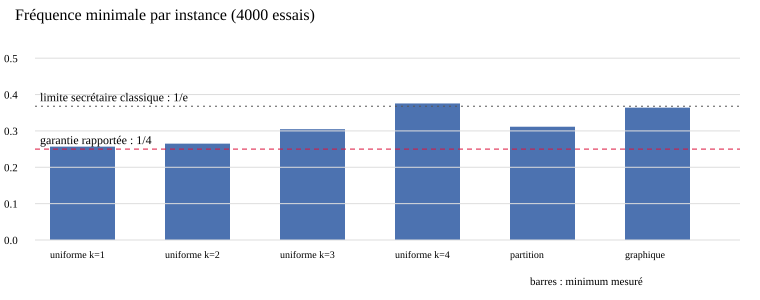

In [5]:
using Microsoft.DotNet.Interactive.Formatting;

record Svg(string Content);
Formatter.Register<Svg>((v, w) => w.Write(v.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
// Les barres utilisent les fréquences effectivement produites par le banc précédent.
var barres = instances.Select((x, i) => (x.nom, minimum: resultats[x.nom].freq.Values.Min(), i)).ToArray();
var svg = new System.Text.StringBuilder();
svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='760' height='300' viewBox='0 0 760 300'><rect width='760' height='300' fill='white'/><text x='15' y='20' font-size='16'>Fréquence minimale par instance (4000 essais)</text>");
foreach (var(nom, v, i)in barres)
{
    double x = 50 + i * 115, hauteur = 200 * v / 0.55;
    svg.Append($"<rect x='{x}' y='{240 - hauteur}' width='65' height='{hauteur}' fill='#4c72b0'/><text x='{x}' y='258' font-size='10'>{System.Net.WebUtility.HtmlEncode(nom)}</text>");
}

// Les graduations et les deux repères portent sur la même échelle verticale que les barres.
for (int tick = 0; tick <= 5; tick++)
{
    double v = tick / 10.0, yy = 240 - 200 * v / 0.55;
    svg.Append($"<line x1='35' y1='{yy}' x2='740' y2='{yy}' stroke='#dddddd'/><text x='4' y='{yy + 4}' font-size='11'>{v:F1}</text>");
}

double y = 240 - 200 * 0.25 / 0.55;
svg.Append($"<line x1='35' y1='{y}' x2='740' y2='{y}' stroke='crimson' stroke-dasharray='5 4'/><text x='40' y='{y - 5}' font-size='12'>garantie rapportée : 1/4</text>");
double yE = 240 - 200 * (1 / Math.E) / 0.55;
svg.Append($"<line x1='35' y1='{yE}' x2='740' y2='{yE}' stroke='#555' stroke-dasharray='2 4'/><text x='40' y='{yE - 5}' font-size='12'>limite secrétaire classique : 1/e</text><text x='530' y='285' font-size='11'>barres : minimum mesuré</text></svg>");
display(new Svg(svg.ToString()));


### Lecture du graphique — repères et valeurs observées

Chaque barre correspond à la plus petite fréquence des éléments de l'optimum pour une instance de la cellule précédente. La ligne rouge marque **1/4**, repère de la garantie rapportée ; la ligne grise marque **1/e**, limite asymptotique du secrétaire classique, et ne représente pas une garantie pour chaque rang. L'axe vertical est gradué, et la légende distingue barres mesurées et repères théoriques.

La différence entre une fréquence de 0,257 ou 0,265 et 1/4 doit être lue avec l'incertitude d'échantillonnage. Le Python cite environ quelques millièmes de bruit pour 4 000 essais ; un échantillon légèrement sous 0,25 ne suffirait pas, à lui seul, à réfuter une garantie probabiliste. À l'inverse, une erreur structurelle produisant systématiquement une fréquence beaucoup plus basse mérite un diagnostic du code et des hypothèses.

## Exercice 1 — Le goulot de la partition

Faire varier de 1 à 3 le quota de la première classe, mesurer 4 000 exécutions par quota et rendre le minimum des fréquences des éléments de l'optimum. Comparer les résultats sans supposer une monotonie théorique.

La classe 0 contient plusieurs éléments mais son quota initial est 1. Pour chaque quota proposé, construire un nouvel oracle de partition, recalculer l'optimum puis mesurer séparément la fréquence de chacun de ses éléments. Le **minimum** doit être pris sur cet optimum, qui peut lui-même changer avec le quota. Le contrôle emploie 4 000 essais par quota, compare au banc reproductible et trace la courbe ; discuter la forme observée sans la transformer en théorème de monotonie.

In [6]:
Dictionary<int, double> EffetQuota(int essais = 4000)
{
    // TODO : utiliser Banc pour chaque quota, puis prendre le minimum des fréquences.
    return null;
}

var ex1 = EffetQuota(4000);
if (ex1 == null)
    Console.WriteLine("Exercice 1 à compléter");
else
{
    if (ex1.Count != 3 || ex1.Keys.Any(q => q < 1 || q > 3) || ex1.Values.Any(v => !double.IsFinite(v) || v < 0 || v > 1))
        throw new Exception("Quotas ou fréquences invalides");
    foreach (int q in new[]
    {
        1,
        2,
        3
    }

    )
    {
        var attendu = Banc(valeurs, Partition(classes, new[] { q, 2, 1 }), 4000).freq.Values.Min();
        if (!ex1.ContainsKey(q) || Math.Abs(ex1[q] - attendu) > 1e-12)
            throw new Exception("Fréquence minimale incorrecte pour le quota");
    }

    Console.WriteLine("Trois quotas comparés au banc reproductible, 4000 essais chacun");
    var qsvg = new System.Text.StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='480' height='260'><rect width='480' height='260' fill='white'/><text x='15' y='20'>Minimum de fréquence selon quota</text>");
    foreach (int q in new[]
    {
        1,
        2,
        3
    }

    )
    {
        double h = 180 * ex1[q];
        qsvg.Append($"<rect x='{50 + q * 100}' y='{220 - h}' width='55' height='{h}' fill='#4c72b0'/><text x='{60 + q * 100}' y='240'>quota {q}</text>");
    }

    qsvg.Append("</svg>");
    display(new Svg(qsvg.ToString()));
}


Exercice 1 à compléter


## Exercice 2 — Approcher 1/4

Construire une instance de 10 éléments au plus, avec un des trois oracles, puis examiner la plus petite fréquence de l'optimum. Discuter le bruit statistique avant de comparer à 1/4.

Quelques pistes du source : tester des valeurs positives plus rapprochées, des contraintes fortes sur les meilleurs éléments, ou une autre des trois familles d'oracles. La fonction doit rendre les valeurs et un oracle utilisables par `Banc`, avec au plus dix éléments. Examiner le minimum **parmi les éléments de l'optimum** ; la cellule rejoue ensuite 4 000 essais. Une valeur de 0,249 peut résulter du bruit : comparer plusieurs graines et augmenter le nombre d'essais avant de tirer une conclusion. Même une instance proche ne prouverait pas que l'infimum théorique soit exactement 1/4.

In [7]:
(double[], Func<IEnumerable<int>, bool>)? InstancePresqueUnQuart()
{
    // TODO : renvoyer une instance et son oracle.
    return null;
}

var ex2 = InstancePresqueUnQuart();
if (ex2 == null)
    Console.WriteLine("Exercice 2 à compléter");
else
{
    var(v, ind) = ex2.Value;
    if (v == null || ind == null || v.Length < 2 || v.Length > 10 || v.Any(x => !double.IsFinite(x) || x <= 0) || !ind(Array.Empty<int>()) || Glouton(v, ind).Count == 0)
        throw new Exception("Instance ou oracle invalide");
    var b = Banc(v, ind, 4000, 7);
    Console.WriteLine($"Minimum mesuré {b.freq.Values.Min():F3} ; comparer avec prudence au bruit des 4000 essais");
}


Exercice 2 à compléter


## 4. Le secrétaire classique comme point de comparaison

Pour n=8, le seuil arrondi à n/e observe trois personnes. La formule finie du succès est distincte de sa limite asymptotique 1/e. Le même banc emploie 4 000 tirages.

Sur le rang 1 de huit éléments, le seuil dédié et l'algorithme universel sont comparés sur le même ensemble de poids. La formule finie du seuil vaut (k/n) Σ_{i=k+1}^n 1/(i−1) avec k=3 ; 1/e est sa limite asymptotique, pas cette probabilité finie. Les six ratios E[ALG]/OPT sont calculés à partir des fréquences de ces mêmes expériences.

Pour huit candidats et trois observés, la probabilité de recruter le meilleur par la règle classique est $\frac{k}{n}\sum_{i=k+1}^{n}\frac1{i-1}$ avec $k=3$, soit environ **0,410**. Le source distingue cette formule finie de la limite $1/e$ lorsque $n$ croît. Une stratégie dédiée au rang 1 connaît une contrainte structurelle précise ; l'algorithme rapporté comme universel ne connaît le matroïde qu'au travers de l'oracle. La comparaison sur cette instance éclaire une différence de méthode, sans mesurer à elle seule un « prix de l'universalité » valable pour toutes les instances.

In [8]:
// Le seuil est le maximum observé ; on ne retient que le premier record ultérieur.
int? Classique(double[] v, Random r)
{
    int n = v.Length, obs = Math.Max(1, (int)Math.Round(n / Math.E));
    var ordre = Permutation(n, r);
    double seuil = ordre.Take(obs).Max(i => v[i]);
    foreach (int i in ordre.Skip(obs))
        if (v[i] > seuil)
            return i;
    return null;
}

var rcmp = new Random(11);
int succes = 0;
for (int i = 0; i < 4000; i++)
    if (Classique(valeurs, rcmp) == 0)
        succes++;
// Cette somme est la probabilité finie pour trois observations sur huit, non sa limite 1/e.
double exacte = 3.0 / 8 * Enumerable.Range(4, 5).Sum(i => 1.0 / (i - 1));
Console.WriteLine($"Classique n=8 : {succes / 4000.0:F3}; formule finie={exacte:F3}, limite=1/e={1 / Math.E:F3}");
Console.WriteLine($"Singla rang 1 : fréquence du meilleur={resultats["uniforme k=1"].freq[0]:F3}; repère 1/4");
Console.WriteLine($"Moyenne des six ratios E[ALG]/OPT : {instances.Average(x => resultats[x.nom].moyenne / resultats[x.nom].opt.Sum(i => valeurs[i])):F3}");


Classique n=8 : 0.415; formule finie=0.410, limite=1/e=0.368


Singla rang 1 : fréquence du meilleur=0.257; repère 1/4


Moyenne des six ratios E[ALG]/OPT : 0.442


### Lecture — une probabilité finie et un ratio moyen

La cellule précédente mesure **0,415** pour la règle classique avec huit éléments et 4 000 ordres, contre **0,410** pour la formule finie et **0,368** pour sa limite asymptotique. Le bruit de Monte Carlo explique qu'une estimation ne soit pas exactement la formule. Sur la même instance uniforme de rang 1, le banc de l'algorithme décrit par le source rend une fréquence **0,257** pour le meilleur, comparée au repère de 1/4.

Les six ratios $E[ALG]/OPT$ ont une moyenne de **0,442** dans cette exécution. Ils agrègent des valeurs, alors que la fréquence minimale du graphique précédent porte sur un élément de l'optimum ; les deux réponses ne se substituent pas. Sur ces petites instances et ces tirages, l'algorithme dépasse le repère d'espérance $1/4$ ; aucune de ces observations ne démontre sa garantie générale.

## Exercice 3 — Deux places et événements conjoints

L'ordre de passage est fourni explicitement comme permutation d'indices, pour distinguer les règles de sélection du tirage aléatoire. Observer les premiers `round(n/e)` candidats, puis accepter les valeurs qui dépassent le maximum observé, dans la limite de deux places.

Pour `dernier`, si une place reste libre, accepter le dernier candidat. Pour `deux_derniers`, accepter en outre tout candidat lorsque le nombre de candidats restant à passer égale le nombre de places libres : cela remplit les deux places dès que possible en fin de séquence. Chaque décision utilise uniquement le préfixe révélé. Comparer les probabilités d'accepter les deux meilleurs sur 4 000 permutations, puis mesurer directement l'intersection pour Singla. Multiplier les marginales suppose une indépendance non établie.

Les deux politiques diffèrent lorsque moins de deux éléments dépassent le seuil : `dernier` ajoute au plus le dernier candidat si une place demeure ; `deux_derniers` remplit les places restantes au fil des dernières arrivées lorsqu'il devient nécessaire de les accepter. Les cas de test fixent explicitement l'ordre, puis les 4 000 permutations mesurent chacune des politiques. La cellule effectue **un autre** banc de 4 000 exécutions de Singla pour le rang 2 et compte directement l'événement « les deux meilleurs sont acceptés ».

L'indépendance de deux acceptations n'est pas fournie par les fréquences individuelles. Même si celles-ci sont chacune proches de 0,26, leur produit ne peut remplacer le comptage de l'intersection ; comparer les événements joints directement. Les décisions et rattrapages doivent utiliser uniquement les candidats déjà arrivés.

In [9]:
HashSet<int> SecretaireDeux(double[] v, int[] ordre, string rattrapage)
{
    // TODO : appliquer la règle du seuil et la politique de rattrapage au fil de l'ordre.
    return null;
}

var testOrdre = new[]
{
    0,
    1,
    2,
    3,
    4,
    5
};
var ex3 = SecretaireDeux(new[] { 6.0, 5, 1, 2, 3, 4 }, testOrdre, "dernier");
if (ex3 == null)
    Console.WriteLine("Exercice 3 à compléter");
else
{
    var attendus = new[]
    {
        (new[] { 6.0, 5, 1, 2, 3, 4 }, "dernier", new[] { 5 }),
        (new[] { 6.0, 5, 1, 2, 3, 4 }, "deux_derniers", new[] { 4, 5 }),
        (new[] { 1.0, 2, 3, 6, 5, 4 }, "dernier", new[] { 2, 3 }),
        (new[] { 1.0, 2, 3, 6, 5, 4 }, "deux_derniers", new[] { 2, 3 })
    };
    foreach (var(v, mode, attendu)in attendus)
    {
        var resultat = SecretaireDeux(v, testOrdre, mode);
        if (resultat == null || !resultat.SetEquals(attendu))
            throw new Exception("Sélection incorrecte sur ordre connu ou rattrapage");
    }

    foreach (string mode in new[]
    {
        "dernier",
        "deux_derniers"
    }

    )
    {
        var r = new Random(7);
        int joints = 0;
        for (int i = 0; i < 4000; i++)
        {
            var s = SecretaireDeux(valeurs, Permutation(valeurs.Length, r), mode);
            if (s == null || s.Count > 2 || s.Any(x => x < 0 || x >= valeurs.Length))
                throw new Exception("Sélection invalide");
            if (s.Contains(0) && s.Contains(6))
                joints++;
        }

        Console.WriteLine($"{mode} : P(deux meilleurs)={joints / 4000.0:F3} (4000 essais)");
    }

    var rs = new Random(31);
    int ensemble = 0;
    for (int i = 0; i < 4000; i++)
    {
        var s = Singla(valeurs, Uniforme(2), rs);
        if (s.Contains(0) && s.Contains(6))
            ensemble++;
    }

    Console.WriteLine($"Singla rang 2 : P(deux meilleurs ensemble)={ensemble / 4000.0:F3} (4000 essais)");
}


Exercice 3 à compléter


## Conclusion — une garantie comme question expérimentale

| Geste | Ce qui est calculé | Limite |
|---|---|---|
| Trois matroïdes | Oracles uniforme, partition, graphique et optimum glouton pour les mêmes huit poids | Trois familles finies ne représentent pas tous les matroïdes |
| Ordre virtuel | Échantillon binomial, positions marquées au hasard et glouton des configurations | Une trace unique ne vérifie pas une garantie en probabilité |
| Banc de garantie | Fréquence de chaque élément d'OPT sur six instances × 4 000 essais ; valeur moyenne | Le bruit d'échantillonnage et le choix d'instances limitent les conclusions |
| Secrétaire dédié | 4 000 ordres au rang 1, formule finie et limite $1/e$ | Comparaison sur une instance, pas preuve d'un prix universel |

## À retenir

1. **La garantie rapportée est élément par élément.** Le minimum mesuré sur les uniformes de rang 1 et 2 est 0,257 et 0,265 dans notre sortie ; sa proximité de 1/4 ne prouve pas une borne serrée.
2. **La place disponible change les fréquences sur ce banc.** Les minima montent ici du rang 1 au rang 4 ; la partition impose une contrainte locale distincte d'un simple cardinal global.
3. **La valeur moyenne et une fréquence minimale répondent à des questions différentes.** Les six ratios $E[ALG]/OPT$ de notre sortie ont une moyenne de 0,442 ; chaque élément de l'optimum reste visible séparément dans le tableau.
4. **Une garantie peut aider à tester une implémentation.** Le Python rapporte qu'un ordre virtuel mal entrelacé produisait un résultat très bas ; notre propre banc et nos contrôles vérifient le comportement des cellules présentes, sans prouver la garantie universelle.
5. **Les événements joints se mesurent comme tels.** Deux probabilités marginales ne déterminent pas leur intersection sans hypothèse supplémentaire ; l'exercice 3 la compte directement.

## Vérifiez votre compréhension

1. Quelles sont les deux informations structurelles données à l'algorithme, et pourquoi leur économie rend-elle la question difficile ?
2. Pourquoi la garantie élément par élément implique-t-elle un ratio moyen, et pourquoi la réciproque ne suit-elle pas ?
3. Pourquoi la formule finie du secrétaire à huit éléments, son estimation Monte Carlo et la limite $1/e$ ne coïncident-elles pas exactement ?
4. Pourquoi une classe de partition à quota 1 peut-elle freiner l'acceptation d'un élément très lourd ?

<details><summary>Éléments de réponse</summary>

1. Le nombre d'éléments et l'oracle d'indépendance ; ni la famille explicite ni une distribution connue des valeurs ne sont nécessaires à la règle rapportée.
2. La linéarité de l'espérance somme les poids multipliés par leurs probabilités ; une moyenne globale élevée peut néanmoins cacher un élément rarement accepté.
3. La formule correspond à $n=8$, le Monte Carlo est une estimation bruitée, et $1/e$ décrit la limite quand $n$ grandit.
4. Plusieurs éléments de cette classe se disputent une seule place ; la structure de la contrainte compte en plus de la valeur individuelle.
</details>

## Pour aller plus loin

[Source Python](Complexity-04d-Secretaire-Matroidal-Python.ipynb) · [04b — les conjectures en ligne](Complexity-04b-OnlineConjectures-Secretary-KServer-Python.ipynb) · [04c — k-server et WFA](Complexity-04c-KServer-WorkFunction-Python.ipynb) · [05 — compter](Complexity-05-CountingHarder-Permanent-Python.ipynb).

**Références rapportées par le Python** : Singla, *The Matroid Secretary Conjecture is True* ; Babaioff, Immorlica et Kleinberg, *Matroids, secretary problems, and online mechanisms* ; Lindley et Dynkin sur le secrétaire classique ; Kleinberg sur le multiple-choice secretary ; Coester, Koutsoupias et Zbysiński sur le k-server. Le source les cite pour le contexte ; aucune lecture directe de ces documents externes n'est revendiquée pour ce port.